# Non-target effects and efficiency: presentation figures

Three slide figures (16:9) for the section on whether augmentation affected other species, and on computational efficiency:

1. **Change in non-target and any-fish AP50**: estimate and 95% CI for each model (did augmentation hurt anything else?)
2. **Non-target AP50, baseline vs augmented**: the absolute values behind figure 1
3. **Augmentation vs a bigger model**: focus-species AP50 against computational cost (augmented Detection M 0.424 vs baseline Detection L 0.373)

**Data.** The values are copied from the analysis of the pooled out-of-fold test predictions (120 runs, seeds averaged), so no data files are needed.
Detection is scored with box IoU and segmentation with mask IoU. *Non-target* = mean AP50 over the 17 classes with ≥20 instances that were
not augmented. *Any-fish* = class-agnostic AP50 over all fish. CIs are 95% paired block-bootstrap intervals (2,000 resamples of
49 temporal blocks), not adjusted for multiple comparisons.

Set `THEME` to `'light'` or `'dark'`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

THEME = 'light'      # 'light' or 'dark'
SAVE = True
DPI = 150
FS = (13.33, 7.5)

## Data

In [2]:
SETUPS = ['detect_s', 'detect_m', 'detect_l', 'segment_s', 'segment_m', 'segment_l']
LAB = {'detect_s': 'Detection S', 'detect_m': 'Detection M', 'detect_l': 'Detection L',
       'segment_s': 'Segmentation S', 'segment_m': 'Segmentation M', 'segment_l': 'Segmentation L'}

# absolute AP50: (baseline, augmented)
NONTARGET = {'detect_s': (0.2615, 0.2566), 'detect_m': (0.2958, 0.2952), 'detect_l': (0.2939, 0.3095),
             'segment_s': (0.2576, 0.2636), 'segment_m': (0.2753, 0.3016), 'segment_l': (0.2921, 0.3120)}
ANYFISH = {'detect_s': (0.6704, 0.6673), 'detect_m': (0.6935, 0.6870), 'detect_l': (0.6806, 0.6724),
           'segment_s': (0.6761, 0.6670), 'segment_m': (0.6890, 0.6980), 'segment_l': (0.6797, 0.6836)}

# change (augmented - baseline): [estimate, 95% CI low, 95% CI high]
D_NONTARGET = {'detect_s': [-0.005, -0.029, 0.031], 'detect_m': [-0.001, -0.016, 0.021], 'detect_l': [0.016, -0.007, 0.036],
               'segment_s': [0.006, -0.010, 0.023], 'segment_m': [0.026, 0.008, 0.051], 'segment_l': [0.020, -0.001, 0.049]}
D_ANYFISH = {'detect_s': [-0.003, -0.016, 0.012], 'detect_m': [-0.007, -0.019, 0.005], 'detect_l': [-0.008, -0.019, 0.001],
             'segment_s': [-0.009, -0.022, 0.004], 'segment_m': [0.009, -0.006, 0.027], 'segment_l': [0.004, -0.006, 0.017]}

# focus-species mean AP50 and model cost
FOCUS_BASE = {'detect_s': 0.2672, 'detect_m': 0.3355, 'detect_l': 0.3727, 'segment_s': 0.2393, 'segment_m': 0.3084, 'segment_l': 0.3608}
FOCUS_AUG = {'detect_s': 0.3572, 'detect_m': 0.4240, 'detect_l': 0.4404, 'segment_s': 0.3553, 'segment_m': 0.4576, 'segment_l': 0.4444}
GFLOPS = {'detect_s': 95, 'detect_m': 305, 'detect_l': 380, 'segment_s': 153, 'segment_m': 533, 'segment_l': 609}   # per 1280 px image
PARAMS_M = {'detect_s': 10.0, 'detect_m': 21.9, 'detect_l': 26.3, 'segment_s': 11.5, 'segment_m': 27.1, 'segment_l': 31.5}
# paired comparison: augmented Detection M - baseline Detection L, focus-species AP50 [est, CI low, CI high]
AUG_M_VS_BASE_L = [0.051, 0.011, 0.107]

## Style

In [3]:
THEMES = {
    'light': dict(bg='#ffffff', ink='#0b0b0b', ink2='#52514e', grid='#e1e0d9', axis='#898781', base='#a3a29b',
                  blue='#2a78d6', orange='#eb6834'),
    'dark':  dict(bg='#0f1b2d', ink='#f0efec', ink2='#c3c2b7', grid='#26354b', axis='#6d7a8e', base='#7f8a9b',
                  blue='#4a90e8', orange='#e2683a'),
}
T = THEMES[THEME]
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 16, 'text.color': T['ink'],
                     'axes.labelcolor': T['ink2'], 'axes.edgecolor': T['axis'], 'xtick.color': T['ink2'],
                     'ytick.color': T['ink2'], 'axes.facecolor': T['bg'], 'figure.facecolor': T['bg'],
                     'savefig.facecolor': T['bg'], 'axes.titlesize': 20, 'axes.titleweight': 'bold',
                     'axes.titlecolor': T['ink'], 'axes.titlelocation': 'left', 'axes.titlepad': 14,
                     'legend.frameon': False, 'legend.fontsize': 15})

def clean(ax, grid='y'):
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
    if grid: ax.grid(axis=grid, color=T['grid'], lw=1); ax.set_axisbelow(True)
    ax.tick_params(length=0)

def save(fig, name):
    if SAVE:
        for ext in ('png', 'pdf'): fig.savefig(f'{name}_{THEME}.{ext}', dpi=DPI)
    plt.show()

## Figure 1: Change in non-target and any-fish AP50
*"Changes in non-target performance were generally small, while class-agnostic detection remained relatively stable."*
Filled dot = CI excludes zero (only Segmentation M non-target, an improvement).

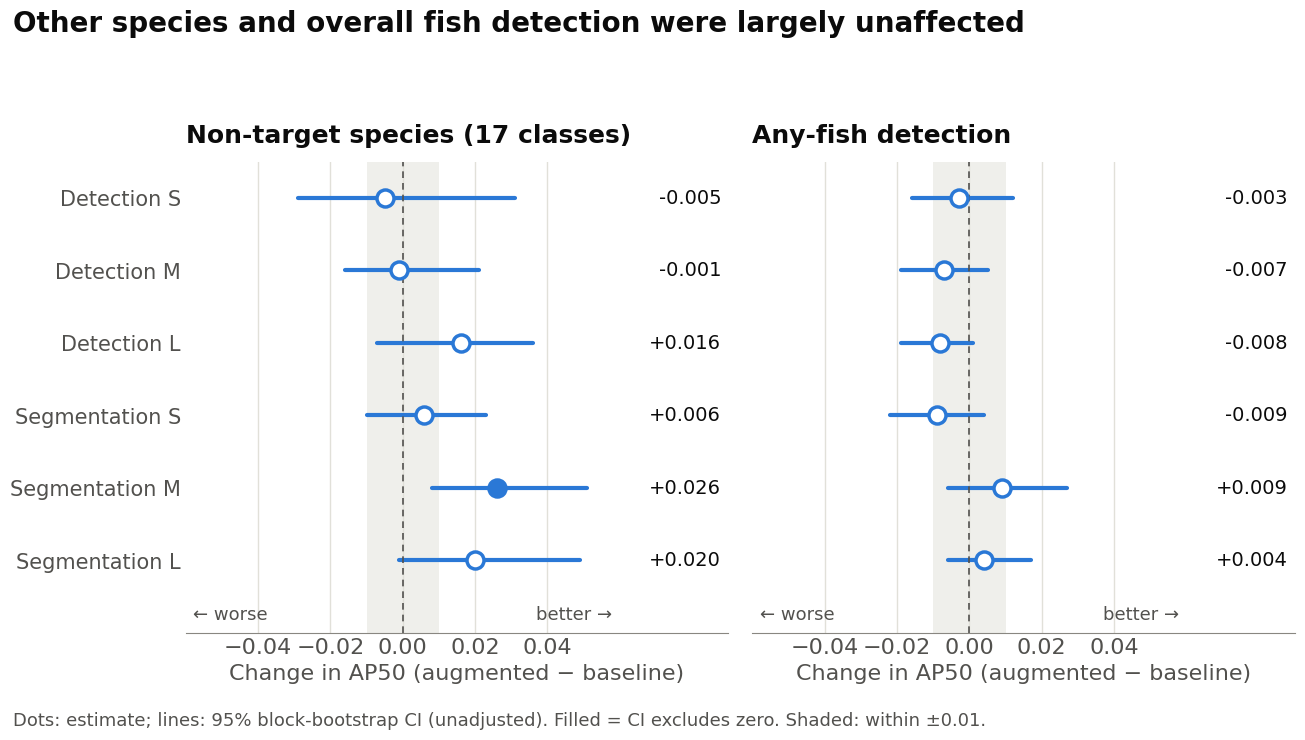

In [4]:
fig, axs = plt.subplots(1, 2, figsize=FS, sharey=True)
order = SETUPS[::-1]
for ax, data, title in [(axs[0], D_NONTARGET, 'Non-target species (17 classes)'), (axs[1], D_ANYFISH, 'Any-fish detection')]:
    ax.axvspan(-0.01, 0.01, color=T['grid'], alpha=0.5, lw=0, zorder=0)   # ±0.01 band: negligible change
    for i, s in enumerate(order):
        e, lo, hi = data[s]; sig = lo > 0 or hi < 0
        ax.plot([lo, hi], [i, i], color=T['blue'], lw=3, solid_capstyle='round')
        ax.scatter(e, i, s=150, color=T['blue'] if sig else T['bg'], edgecolor=T['blue'], lw=2.5, zorder=3)
        ax.text(0.088, i, f'{e:+.3f}', va='center', ha='right', fontsize=14)
    ax.axvline(0, color=T['ink2'], lw=1.2, ls=(0, (4, 3)))
    ax.set_xlim(-0.06, 0.09); ax.set_xticks([-0.04, -0.02, 0, 0.02, 0.04]); ax.set_title(title, fontsize=18)
    clean(ax, grid='x'); ax.spines['left'].set_visible(False); ax.set_xlabel('Change in AP50 (augmented − baseline)')
axs[0].set_yticks(range(6)); axs[0].set_yticklabels([LAB[s] for s in order], fontsize=15)
for ax in axs:
    ax.set_ylim(-1.0, 5.5)
    ax.text(-0.058, -0.75, '← worse', fontsize=13, color=T['ink2'], va='center')
    ax.text(0.058, -0.75, 'better →', fontsize=13, color=T['ink2'], va='center', ha='right')
fig.suptitle('Other species and overall fish detection were largely unaffected', x=0.02, ha='left',
             fontsize=20, fontweight='bold', color=T['ink'])
fig.text(0.02, 0.025, 'Dots: estimate; lines: 95% block-bootstrap CI (unadjusted). Filled = CI excludes zero. '
         'Shaded: within ±0.01.', fontsize=13, color=T['ink2'])
fig.tight_layout(rect=(0, 0.05, 1, 0.93)); save(fig, 'nontarget_fig1_changes')

## Figure 2: Non-target AP50, baseline vs augmented

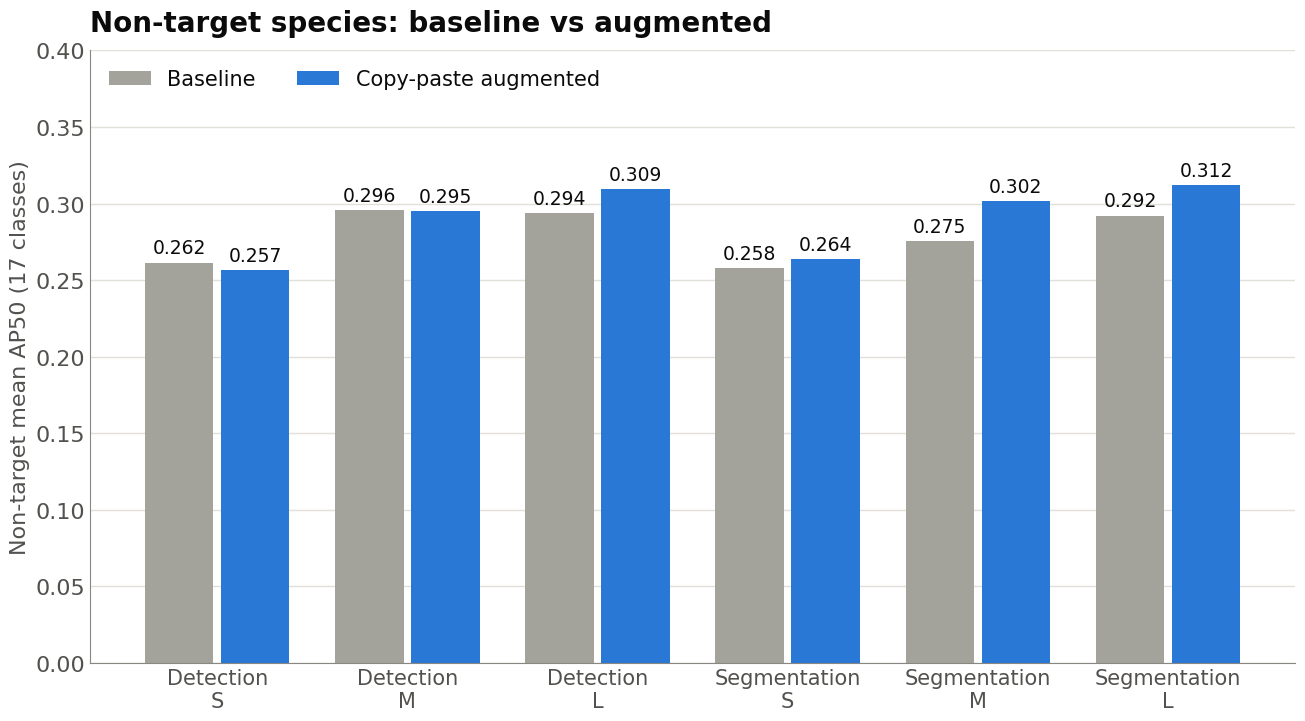

In [5]:
fig, ax = plt.subplots(figsize=FS)
x = np.arange(6); w = 0.36
for i, s in enumerate(SETUPS):
    b, a = NONTARGET[s]
    ax.bar(i - w / 2 - 0.02, b, w, color=T['base'], label='Baseline' if i == 0 else None)
    ax.bar(i + w / 2 + 0.02, a, w, color=T['blue'], label='Copy-paste augmented' if i == 0 else None)
    ax.text(i - w / 2 - 0.02, b + 0.006, f'{b:.3f}', ha='center', fontsize=13.5)
    ax.text(i + w / 2 + 0.02, a + 0.006, f'{a:.3f}', ha='center', fontsize=13.5)
ax.set_xticks(x); ax.set_xticklabels([LAB[s].replace(' ', '\n', 1) for s in SETUPS], fontsize=15)
ax.set_ylim(0, 0.4); ax.set_ylabel('Non-target mean AP50 (17 classes)'); clean(ax)
ax.legend(loc='upper left', ncol=2)
ax.set_title('Non-target species: baseline vs augmented')
fig.tight_layout(); save(fig, 'nontarget_fig2_absolute')

## Figure 3: Augmentation vs a bigger model
*"The augmented medium detection model achieved a focus-species mean AP50 of 0.424, compared with 0.373 for the baseline
large detection model, despite requiring fewer parameters and computational operations."*

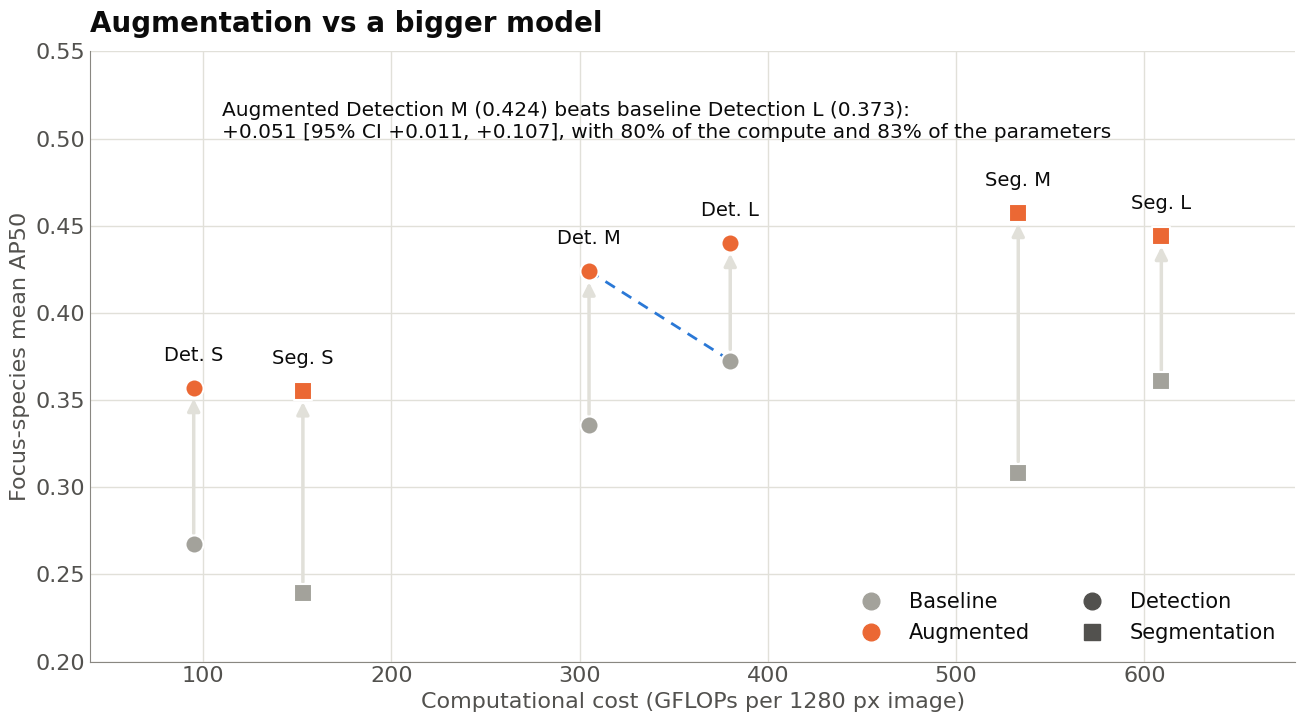

In [6]:
fig, ax = plt.subplots(figsize=FS)
for s in SETUPS:
    b, a, g = FOCUS_BASE[s], FOCUS_AUG[s], GFLOPS[s]; mk = 'o' if s.startswith('detect') else 's'
    ax.annotate('', (g, a), (g, b), arrowprops=dict(arrowstyle='-|>', color=T['grid'], lw=2.5, mutation_scale=18,
                                                   shrinkA=8, shrinkB=8))
    ax.scatter(g, b, s=170, marker=mk, color=T['base'], zorder=3, edgecolor=T['bg'], lw=1.5)
    ax.scatter(g, a, s=170, marker=mk, color=T['orange'], zorder=3, edgecolor=T['bg'], lw=1.5)
    ax.text(g, a + 0.013, LAB[s].replace('Detection', 'Det.').replace('Segmentation', 'Seg.'), fontsize=14,
            ha='center', va='bottom')
am, bl = FOCUS_AUG['detect_m'], FOCUS_BASE['detect_l']; d, lo, hi = AUG_M_VS_BASE_L
ax.plot([GFLOPS['detect_m'], GFLOPS['detect_l']], [am, bl], color=T['blue'], lw=2, ls=(0, (4, 3)))
ax.text(110, 0.51, f'Augmented Detection M ({am:.3f}) beats baseline Detection L ({bl:.3f}):\n'
        f'{d:+.3f} [95% CI {lo:+.3f}, {hi:+.3f}], with {GFLOPS["detect_m"] / GFLOPS["detect_l"]:.0%} of the compute '
        f'and {PARAMS_M["detect_m"] / PARAMS_M["detect_l"]:.0%} of the parameters', fontsize=14.5, va='center')
ax.set_xlim(40, 680); ax.set_ylim(0.2, 0.55)
ax.set_xlabel('Computational cost (GFLOPs per 1280 px image)'); ax.set_ylabel('Focus-species mean AP50')
clean(ax, grid='both')
ax.legend(handles=[Line2D([], [], marker='o', ls='', ms=12, color=T['base']), Line2D([], [], marker='o', ls='', ms=12, color=T['orange']),
                   Line2D([], [], marker='o', ls='', ms=12, color=T['ink2']), Line2D([], [], marker='s', ls='', ms=12, color=T['ink2'])],
          labels=['Baseline', 'Augmented', 'Detection', 'Segmentation'], loc='lower right', ncol=2)
ax.set_title('Augmentation vs a bigger model')
fig.tight_layout(); save(fig, 'nontarget_fig3_efficiency')

## Numbers for the script

In [7]:
for s in SETUPS:
    print(f'{LAB[s]:15s} non-target {NONTARGET[s][0]:.3f} -> {NONTARGET[s][1]:.3f} ({D_NONTARGET[s][0]:+.3f})   '
          f'any-fish {ANYFISH[s][0]:.3f} -> {ANYFISH[s][1]:.3f} ({D_ANYFISH[s][0]:+.3f})')
print('Largest non-target change:', max(abs(v[0]) for v in D_NONTARGET.values()),
      '| largest any-fish change:', max(abs(v[0]) for v in D_ANYFISH.values()))

Detection S     non-target 0.262 -> 0.257 (-0.005)   any-fish 0.670 -> 0.667 (-0.003)
Detection M     non-target 0.296 -> 0.295 (-0.001)   any-fish 0.694 -> 0.687 (-0.007)
Detection L     non-target 0.294 -> 0.309 (+0.016)   any-fish 0.681 -> 0.672 (-0.008)
Segmentation S  non-target 0.258 -> 0.264 (+0.006)   any-fish 0.676 -> 0.667 (-0.009)
Segmentation M  non-target 0.275 -> 0.302 (+0.026)   any-fish 0.689 -> 0.698 (+0.009)
Segmentation L  non-target 0.292 -> 0.312 (+0.020)   any-fish 0.680 -> 0.684 (+0.004)
Largest non-target change: 0.026 | largest any-fish change: 0.009
